In [2]:
import sys
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Add parent directories to path for imports
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

from db.db_azure import connect

# Set display options
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)

# Set plot style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

AZURE DBSERVER cdcfdomestictobacco.database.windows.net


## 1. Load Reviews with Non-Null Sweet Level

In [3]:
# Query to get reviews with non-null sweet level
query = """
SELECT 
    p.id AS product_id,
    p.product_name,
    p.site_name,
    p.site_tag,
    p.brand,
    p.site_category,
    r.id AS review_id,
    r.review_date,
    r.review_text,
    r.rating,
    r.verified,
    case when r.sweet_level is null then 1 else r.sweet_level + 1 end as sweet_level,
    case when r.iced_level is null then 1 else r.iced_level + 1 end as iced_level,
    r.author,
    r.variant
FROM 
    ecig_reviews r
INNER JOIN 
    ecig_product p ON p.id = r.product_id
WHERE 
    (r.sweet_level IS NOT NULL
    or r.iced_level IS NOT NULL)
    AND p.site_name = 'GETPOP'
        AND r.date_inserted < '2026-07-01'

ORDER BY 
    r.date_inserted DESC
"""

# Connect and fetch data
conn = connect()
df_reviews = pd.read_sql(query, conn)
conn.close()

print(f"Total reviews with sweet level: {len(df_reviews)}")


/var/folders/r6/bbh6nj696l1_bkjr135f4whj0sdf0t/T/ipykernel_18533/1019442170.py:35: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_reviews = pd.read_sql(query, conn)


Total reviews with sweet level: 2422


## 2. Basic Statistics

In [4]:
# Summary statistics
print("Dataset Shape:", df_reviews.shape)
print("\n" + "="*60)
print(f"Unique Products with Sweet Level: {df_reviews['product_id'].nunique()}")
print(f"Total Reviews with Sweet Level: {len(df_reviews)}")
print(f"Average Reviews per Product: {len(df_reviews) / df_reviews['product_id'].nunique():.2f}")
print("="*60)
print("\nSweet Level Statistics:")
print(df_reviews['sweet_level'].describe())

Dataset Shape: (2422, 15)

Unique Products with Sweet Level: 1083
Total Reviews with Sweet Level: 2422
Average Reviews per Product: 2.24

Sweet Level Statistics:
count    2422.000000
mean        3.791908
std         1.065613
min         1.000000
25%         3.000000
50%         4.000000
75%         5.000000
max         5.000000
Name: sweet_level, dtype: float64


Reviews by Site:
site_name
GETPOP    2422
Name: count, dtype: int64


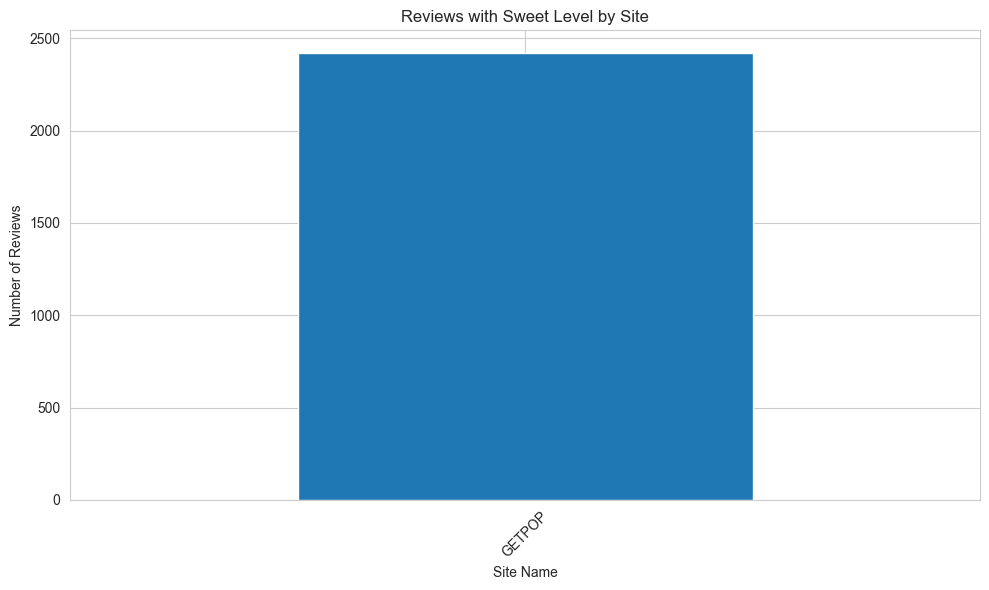

In [5]:
# Distribution by site
print("Reviews by Site:")
site_counts = df_reviews['site_name'].value_counts()
print(site_counts)

# Plot distribution
plt.figure(figsize=(10, 6))
site_counts.plot(kind='bar')
plt.title('Reviews with Sweet Level by Site')
plt.xlabel('Site Name')
plt.ylabel('Number of Reviews')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [12]:
df_some_sweet = df_reviews[df_reviews['sweet_level'] > 1]
print(f"Unique Products with Sweet Level > 1: {df_some_sweet['product_id'].nunique()}")

some_sweet = df_some_sweet['product_id'].nunique()
all_count = df_reviews['product_id'].nunique()
print(some_sweet/all_count, some_sweet, all_count)
print("Sweet > 1, Dataset Shape:", df_some_sweet.shape[0])
print("Sweet All, Dataset Shape:", df_reviews.shape[0])
print(df_some_sweet.shape[0]/df_reviews.shape[0])

Unique Products with Sweet Level > 1: 1066
0.984302862419206 1066 1083
Sweet > 1, Dataset Shape: 2346
Sweet All, Dataset Shape: 2422
0.9686209744013212


## 3. Sweet Level Analysis

Sweet Level Value Counts:
             count       pct
sweet_level                 
1               76  0.031379
2              196  0.080925
3              635  0.262180
4              764  0.315442
5              751  0.310074


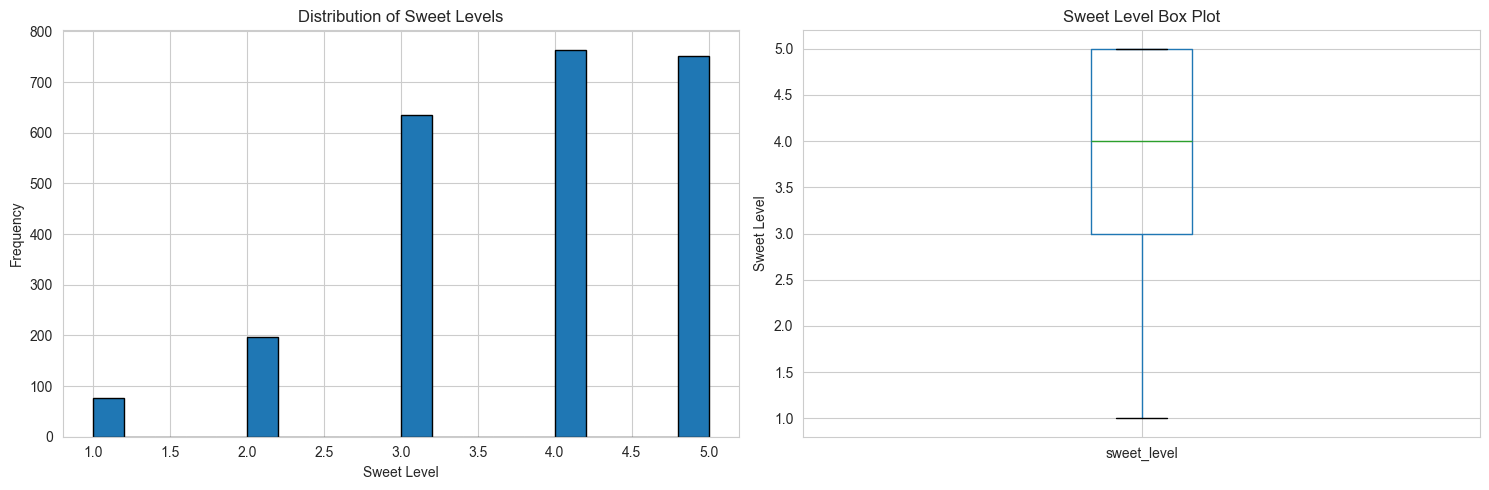

In [28]:
# Sweet level distribution
print("Sweet Level Value Counts:")
df_vc = (df_reviews['sweet_level'].value_counts().sort_index().to_frame())
df_vc['pct'] = df_vc['count']/df_reviews.shape[0]
print(df_vc)

# Visualize sweet level distribution
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Histogram
df_reviews['sweet_level'].hist(bins=20, ax=axes[0], edgecolor='black')
axes[0].set_title('Distribution of Sweet Levels')
axes[0].set_xlabel('Sweet Level')
axes[0].set_ylabel('Frequency')

# Box plot
df_reviews.boxplot(column='sweet_level', ax=axes[1])
axes[1].set_title('Sweet Level Box Plot')
axes[1].set_ylabel('Sweet Level')

plt.tight_layout()
plt.show()

In [7]:
196 + 635 + 764 + 751

2346

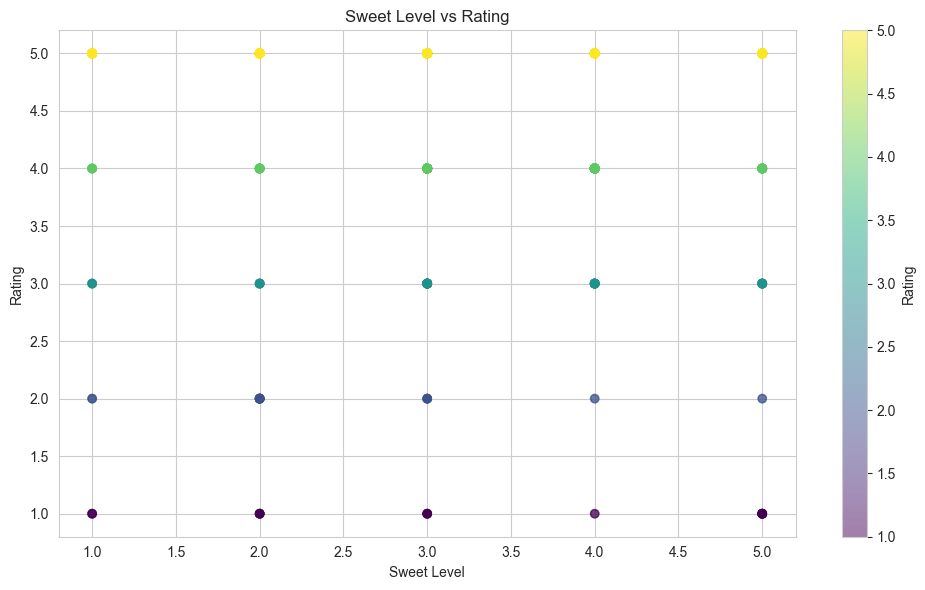


Correlation between Sweet Level and Rating:
             sweet_level    rating
sweet_level     1.000000  0.170634
rating          0.170634  1.000000


In [29]:
# Sweet level vs Rating correlation
if df_reviews['rating'].notna().sum() > 0:
    fig, ax = plt.subplots(figsize=(10, 6))
    scatter = ax.scatter(df_reviews['sweet_level'], df_reviews['rating'], 
                        alpha=0.5, c=df_reviews['rating'], cmap='viridis')
    ax.set_xlabel('Sweet Level')
    ax.set_ylabel('Rating')
    ax.set_title('Sweet Level vs Rating')
    plt.colorbar(scatter, label='Rating')
    plt.tight_layout()
    plt.show()
    
    # Calculate correlation
    correlation = df_reviews[['sweet_level', 'rating']].corr()
    print("\nCorrelation between Sweet Level and Rating:")
    print(correlation)

## 4. Product-Level Analysis

In [30]:
# Aggregate by product
product_summary = df_reviews.groupby(['product_id', 'product_name', 'brand']).agg({
    'sweet_level': ['mean', 'std', 'min', 'max', 'count'],
    'rating': ['mean', 'count'],
    'iced_level': 'mean'
}).round(2)

product_summary.columns = ['_'.join(col).strip() for col in product_summary.columns.values]
product_summary = product_summary.reset_index()
product_summary = product_summary.sort_values('sweet_level_count', ascending=False)

print(f"Total products with sweet level reviews: {len(product_summary)}")
print("\nTop 10 Products by Number of Sweet Level Reviews:")
product_summary.head(10)

Total products with sweet level reviews: 0

Top 10 Products by Number of Sweet Level Reviews:


,product_id,product_name,brand,sweet_level_mean,sweet_level_std,sweet_level_min,sweet_level_max,sweet_level_count,rating_mean,rating_count,iced_level_mean


In [31]:
# Products with highest average sweet level (min 5 reviews)
high_sweet = product_summary[product_summary['sweet_level_count'] >= 5].sort_values(
    'sweet_level_mean', ascending=False
).head(10)

print("Top 10 Sweetest Products (min 5 reviews):")
print(high_sweet[['product_name', 'brand', 'sweet_level_mean', 'sweet_level_count', 'rating_mean']])

Top 10 Sweetest Products (min 5 reviews):
Empty DataFrame
Columns: [product_name, brand, sweet_level_mean, sweet_level_count, rating_mean]
Index: []


## 5. Brand Analysis

Brand Summary (Top 15 by review count):
Empty DataFrame
Columns: [brand, sweet_level_mean, sweet_level_std, sweet_level_count, rating_mean, product_id_nunique]
Index: []


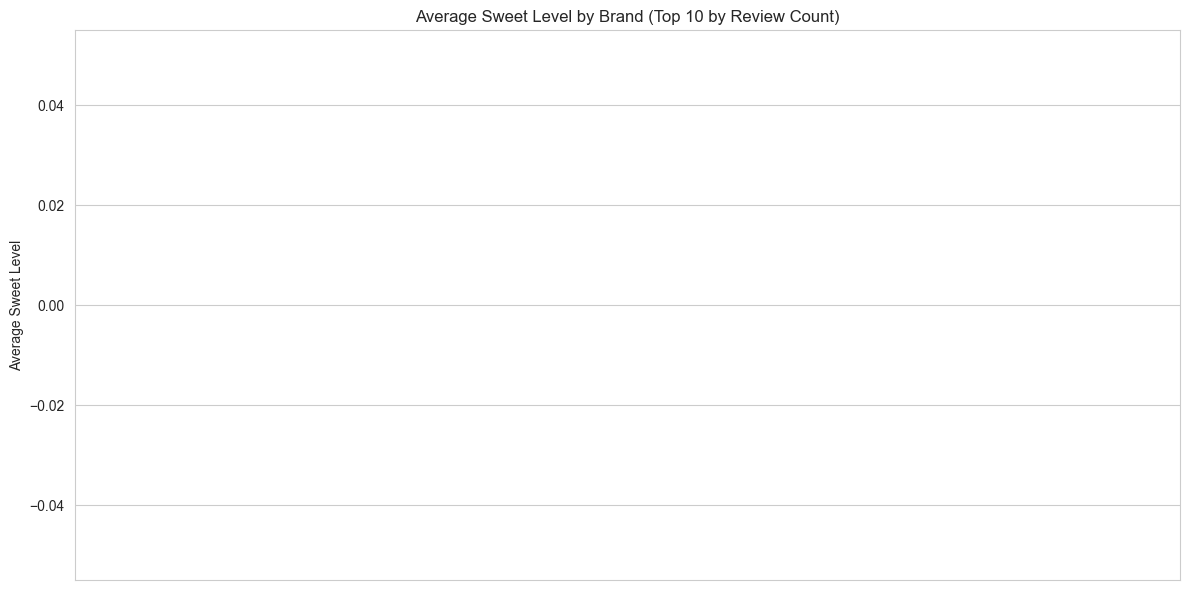

In [32]:
# Aggregate by brand
brand_summary = df_reviews.groupby('brand').agg({
    'sweet_level': ['mean', 'std', 'count'],
    'rating': 'mean',
    'product_id': 'nunique'
}).round(2)

brand_summary.columns = ['_'.join(col).strip() for col in brand_summary.columns.values]
brand_summary = brand_summary.reset_index()
brand_summary = brand_summary.sort_values('sweet_level_count', ascending=False)

print("Brand Summary (Top 15 by review count):")
print(brand_summary.head(15))

# Visualize top brands
top_brands = brand_summary.head(10)
fig, ax = plt.subplots(figsize=(12, 6))
x = range(len(top_brands))
ax.bar(x, top_brands['sweet_level_mean'], alpha=0.7)
ax.errorbar(x, top_brands['sweet_level_mean'], 
            yerr=top_brands['sweet_level_std'], 
            fmt='none', ecolor='red', capsize=5)
ax.set_xticks(x)
ax.set_xticklabels(top_brands['brand'], rotation=45, ha='right')
ax.set_ylabel('Average Sweet Level')
ax.set_title('Average Sweet Level by Brand (Top 10 by Review Count)')
plt.tight_layout()
plt.show()

## 6. Sweet vs Iced Relationship

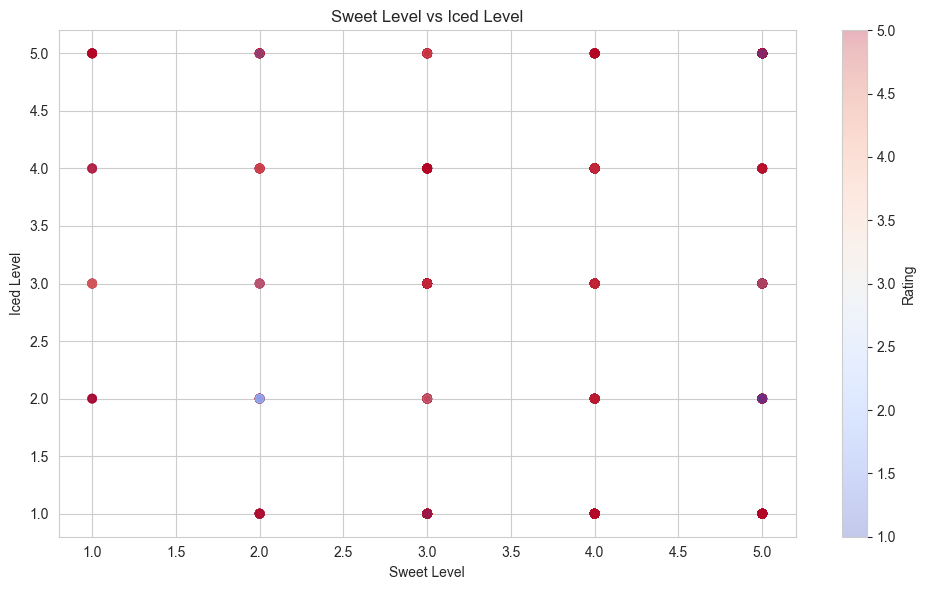


Correlation between Sweet Level and Iced Level:
             sweet_level  iced_level
sweet_level     1.000000    0.100261
iced_level      0.100261    1.000000


In [33]:
# Compare sweet and iced levels
if df_reviews['iced_level'].notna().sum() > 0:
    fig, ax = plt.subplots(figsize=(10, 6))
    scatter = ax.scatter(df_reviews['sweet_level'], df_reviews['iced_level'], 
                        alpha=0.3, c=df_reviews['rating'], cmap='coolwarm')
    ax.set_xlabel('Sweet Level')
    ax.set_ylabel('Iced Level')
    ax.set_title('Sweet Level vs Iced Level')
    plt.colorbar(scatter, label='Rating')
    plt.tight_layout()
    plt.show()
    
    # Correlation
    if df_reviews['iced_level'].notna().sum() > 1:
        correlation = df_reviews[['sweet_level', 'iced_level']].corr()
        print("\nCorrelation between Sweet Level and Iced Level:")
        print(correlation)

## 7. Sample Review Text Analysis

In [34]:
# Show examples of high sweet level reviews
high_sweet_reviews = df_reviews.nlargest(5, 'sweet_level')[[
    'product_name', 'sweet_level', 'rating', 'review_text'
]]

print("Sample High Sweet Level Reviews:\n")
for idx, row in high_sweet_reviews.iterrows():
    print(f"Product: {row['product_name']}")
    print(f"Sweet Level: {row['sweet_level']} | Rating: {row['rating']}")
    print(f"Review: {row['review_text'][:200]}...")
    print("-" * 80)
    print()

Sample High Sweet Level Reviews:

Product: Kado Bar NI40K Sour-Nic Control Sour Apple Hard Candy
Sweet Level: 5 | Rating: 5.0
Review: My favorite vape. Just the right amount of sour and love you can control the sourness and the nicotine level...
--------------------------------------------------------------------------------

Product: Geek Bar Pulse 15000 Sour Gush (Cherry Raspberry Lime)
Sweet Level: 5 | Rating: 5.0
Review: It has a sour tangy taste with some cherry to it. It is one of my favorites absolutely love. One of the two that I buy....
--------------------------------------------------------------------------------

Product: RAZ VUE 50K Pod White Gummy
Sweet Level: 5 | Rating: 5.0
Review: sweet...
--------------------------------------------------------------------------------

Product: RAZ LTX 25K Strawberry Burst
Sweet Level: 5 | Rating: 5.0
Review: My favorite...
--------------------------------------------------------------------------------

Product: RAZ TN9000 Strawberr

In [35]:
# Show examples of low sweet level reviews
low_sweet_reviews = df_reviews.nsmallest(5, 'sweet_level')[[
    'product_name', 'sweet_level', 'rating', 'review_text'
]]

print("Sample Low Sweet Level Reviews:\n")
for idx, row in low_sweet_reviews.iterrows():
    print(f"Product: {row['product_name']}")
    print(f"Sweet Level: {row['sweet_level']} | Rating: {row['rating']}")
    print(f"Review: {row['review_text'][:200]}...")
    print("-" * 80)
    print()

Sample Low Sweet Level Reviews:

Product: Hyppe Infiniti 50K Dubai Chocolate
Sweet Level: 1 | Rating: 5.0
Review: Tastey...
--------------------------------------------------------------------------------

Product: Geek Bar Pulse 15000 White Gummy Ice
Sweet Level: 1 | Rating: 5.0
Review: Great...
--------------------------------------------------------------------------------

Product: Fume Infinity Plus 4500 Mint Ice
Sweet Level: 1 | Rating: 5.0
Review: These are fantastic. Only wish they came in 20 or 30k puffs...
--------------------------------------------------------------------------------

Product: Foger Switch Pro 30K Pod Tobacco
Sweet Level: 1 | Rating: 5.0
Review: Just great...
--------------------------------------------------------------------------------

Product: Foger Switch Pro 30K Pod Tobacco
Sweet Level: 1 | Rating: 5.0
Review: The perfect tobacco flavor. It's hard to find a good tobacco flavor. But foger has perfected it...
-------------------------------------------

## 8. Export Results

In [36]:
# Export product summary to CSV
output_dir = 'nlp/reviews/results'
os.makedirs(output_dir, exist_ok=True)

product_summary.to_csv(f'{output_dir}/sweet_level_product_summary.csv', index=False)
brand_summary.to_csv(f'{output_dir}/sweet_level_brand_summary.csv', index=False)
df_reviews.to_csv(f'{output_dir}/sweet_level_reviews_full.csv', index=False)

print(f"Results exported to {output_dir}/")
print(f"- sweet_level_product_summary.csv ({len(product_summary)} products)")
print(f"- sweet_level_brand_summary.csv ({len(brand_summary)} brands)")
print(f"- sweet_level_reviews_full.csv ({len(df_reviews)} reviews)")

Results exported to nlp/reviews/results/
- sweet_level_product_summary.csv (0 products)
- sweet_level_brand_summary.csv (0 brands)
- sweet_level_reviews_full.csv (2422 reviews)
